<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 50 — XGBoost Regresyon: Usta ve Çıraklarla Ev Fiyatı">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-50-7C3AED?style=for-the-badge" alt="Gün 50">
  <img src="https://img.shields.io/badge/Konu-XGBoost_Regresyon_(Kavram)-F6B84B?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Veri-Kaliforniya_Konut-16A34A?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-EDAE49?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/XGBoost-0F172A?style=for-the-badge" alt="XGBoost">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🧑‍🏫</h3><b>Usta ve çıraklar</b><br><br>Bir ev fiyatı tahmincisi<br>nasıl <b>hatalarından</b><br>ders alır?<br><br></td><td width="25%" valign="top" align="center"><h3>🏘️</h3><b>Altı evlik örnek</b><br><br>Her sayıyı <b>elle</b> hesaplar,<br>sonra gerçek kütüphaneyle<br><b>doğrularız</b><br><br></td><td width="25%" valign="top" align="center"><h3>🎞️</h3><b>Hareketli anlatım</b><br><br>Bölünme, hata avı ve<br><b>Kaliforniya haritası</b><br>tur tur netleşir<br><br></td><td width="25%" valign="top" align="center"><h3>🔧</h3><b>Kara kutu değil</b><br><br>40 satırlık <b>mini XGBoost</b><br>kütüphaneyle aynı sonucu<br>verir<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu dersin sonunda şunları yapabiliyor olacaksınız:**

- 🧑‍🏫 XGBoost'un **"usta + çıraklar"** fikrini kendi cümlelerinizle anlatmak
- 🩹 **Artık** (kalan hata) kavramını ve her ağacın neden artıklara baktığını açıklamak
- 🌳 Küçük bir ağacın evleri **nasıl böldüğünü** ve yaprak değerinin nasıl bulunduğunu **elle hesaplamak**
- 👣 **Öğrenme hızı (η)**, **λ**, **γ** gibi düğmelerin ne işe yaradığını sezgisel olarak bilmek
- 🎓 **Fazla öğrenmeyi** (ezber) grafikten tanımak ve **erken durdurma** fikrini kavramak
- 🗺️ Gerçek Kaliforniya verisinde modelin **tur tur** nasıl netleştiğini izlemek
- 🔧 Kendi **mini XGBoost'unuzu** yazıp gerçek kütüphaneyle karşılaştırmak

> 💡 Bu ders **ilk kez duyanlar** içindir. Formül görürseniz korkmayın: her formülün yanında bir resim, bir benzetme ve bir hesap vardır.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Ders yol haritası: 15 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Araç çantası hazır |
| 💡 2 | [Büyük fikir](#p2) | Tek usta mı, usta + çıraklar mı? |
| 🏘️ 3 | [Altı evlik örnek](#p3) | Herkese aynı fiyatla başla |
| 🩹 4 | [Artıklar](#p4) | Kalan hata, sıradaki öğretmen |
| 🌳 5 | [Küçük ağaç](#p5) | Evleri ikiye böl, hatayı topla |
| 👣 6 | [Küçük adımlar](#p6) | Yaprak değeri ve öğrenme hızı |
| ✅ 7 | [Doğrulama](#p7) | Elle hesap = gerçek XGBoost |
| 🛡️ 8 | [Frenler](#p8) | Aşırı hevesi dizginle: λ ve γ |
| 🎓 9 | [Fazla öğrenme](#p9) | Ezber mi, yetersizlik mi? |
| 🗺️ 10 | [Kaliforniya'da ilk dokunuş](#p10) | Harita tur tur netleşiyor |
| 📈 11 | [Çizgi mi, basamak mı?](#p11) | Gelir–fiyat ilişkisinin gerçek şekli |
| ⚡ 12 | [Neden “extreme”?](#p12) | Hız ve eksik değerle başa çıkış |
| 🧭 13 | [Model neye bakıyor?](#p13) | Önem puanları, SHAP'in sezgisi |
| 🔧 14 | [Sıfırdan XGBoost](#p14) | 40 satırda mini regresör |
| 🎒 15 | [Özet ve ödevler](#p15) | Akılda kalanlar, quiz, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1">
</p>

Önce araç çantamızı açalım: kütüphaneler, renk teması ve iki küçük yardımcı fonksiyon (grafik kaydetme, animasyon kaydetme). `RANDOM_STATE` sabit olduğu için her çalıştırmada **aynı sonuçları** görürsünüz. Model kütüphanesi `xgboost` (Chen ve Guestrin, 2016), yardımcı araçlar `scikit-learn` (Pedregosa vd., 2011).

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import platform
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from xgboost import DMatrix, XGBRegressor

warnings.filterwarnings("ignore")

# ── Sabitler ve klasörler ───────────────────────────────────
RANDOM_STATE = 42
VERI_YOLU = Path("21-housing.csv")
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Görsel tema (notebook boyunca aynı renkler) ──────────────
RENK = {"altin": "#EDAE49", "mor": "#6C5CE7", "pembe": "#D1495B", "mavi": "#2B6CB0",
        "yesil": "#2E9E6B", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#2E4057", "cyan": "#0E9AA7"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    yol = FIG_DIR / f"{ad}.png"
    fig.savefig(yol)
    print(f"💾 Kaydedildi → {yol.as_posix()}")


def gif_kaydet(kare_ciz, n_kare, yol, figsize=(8, 4.5), fps=2, dpi=70):
    """kare_ciz(fig, i) fonksiyonuyla her kareyi çizip animasyonlu GIF olarak kaydeder."""
    fig = plt.figure(figsize=figsize)
    anim = FuncAnimation(fig, lambda i: kare_ciz(fig, i), frames=n_kare)
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"💾 Animasyon → {Path(yol).as_posix()} ({Path(yol).stat().st_size / 1024:.0f} KB)")


def rmse(gercek, tahmin):
    """Kök ortalama kare hata: tahminler gerçekten ortalama kaç birim uzak?"""
    return float(np.sqrt(mean_squared_error(gercek, tahmin)))


print(f"Python {platform.python_version()} · XGBoost {xgboost.__version__} · scikit-learn {sklearn.__version__} · pandas {pd.__version__} · numpy {np.__version__}")

Python 3.13.18 · XGBoost 3.4.1 · scikit-learn 1.9.1 · pandas 3.0.5 · numpy 2.5.3


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2">
</p>

### 💡 2.1 · Tek Usta mı, Usta + Çıraklar mı?

Bir emlak **ustası** düşünün. Bir mahalledeki evin fiyatını **tek bir bakışta** tahmin ediyor ve ara sıra yanılıyor. Şimdi ona **çıraklar** verelim:

1. 🧑‍🏫 **Usta** önce herkese aynı, kaba bir fiyat söyler (örneğin tüm evlerin ortalaması).
2. 🧑‍🎓 **1. çırak** ustanın **yanıldığı yerlere** bakar ve küçük bir düzeltme önerir.
3. 🧑‍🎓 **2. çırak** hâlâ kalan hatalara bakar, o da küçük bir düzeltme ekler.
4. … yüzlerce çırak sonra **hata çok küçülür**.

İşte **XGBoost** (*eXtreme Gradient Boosting*) tam olarak budur: **küçük ağaçlardan oluşan, hatadan öğrenen bir ekip**. Her ağaç **tek başına zayıftır**; birlikte çok güçlüdür.

<p align="center">
  <img src="assets/diyagram_takim.svg" width="100%" alt="Usta ve çıraklar">
</p>

### 📈 2.2 · Aynı Fikri Bir Grafikte Görelim

Gelir arttıkça ev fiyatının **yavaşça yükselip yatay seyrettiği** gürültülü bir eğri üretelim (gerçek veriye benzer). Aynı veriye üç model uyduralım: **tek küçük ağaç**, **1 ağaçlı XGBoost** ve **100 küçük ağaçlı XGBoost ekibi**.

💾 Kaydedildi → outputs/figures/kavram_02_tek_agac_mi_ekip_mi.png


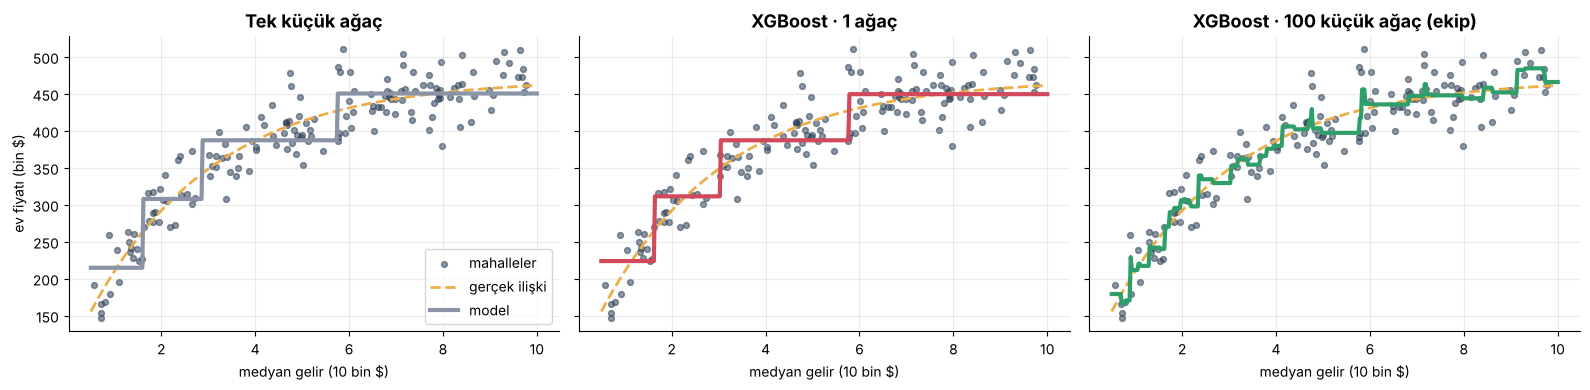

In [2]:
# Gelir (10 bin $) ile fiyat (bin $) arasında gürültülü bir ilişki: tek ağaç mı, 100 küçük ağaçlı ekip mi?
rng = np.random.default_rng(RANDOM_STATE)
gelir = np.sort(rng.uniform(0.5, 10, 160))
gercek_egri = lambda g: 90 + 380 * (1 - np.exp(-0.38 * g))             # gerçek (bilinmeyen) ilişki
fiyat = gercek_egri(gelir) + rng.normal(0, 28, gelir.size)               # ölçüm gürültüsü
Xg = gelir.reshape(-1, 1)
izgara = np.linspace(0.5, 10, 400).reshape(-1, 1)

tek_agac = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE).fit(Xg, fiyat)
xgb_1 = XGBRegressor(n_estimators=1, max_depth=2, learning_rate=1.0, random_state=RANDOM_STATE).fit(Xg, fiyat)
xgb_100 = XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.1, random_state=RANDOM_STATE).fit(Xg, fiyat)

fig, eksen = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, model, ad, renk in zip(eksen, [tek_agac, xgb_1, xgb_100],
                                ["Tek küçük ağaç", "XGBoost · 1 ağaç", "XGBoost · 100 küçük ağaç (ekip)"],
                                [RENK["gri"], RENK["pembe"], RENK["yesil"]]):
    ax.scatter(gelir, fiyat, s=18, color=RENK["koyu"], alpha=0.55, label="mahalleler")
    ax.plot(izgara, gercek_egri(izgara), "--", color=RENK["altin"], lw=2, label="gerçek ilişki")
    ax.plot(izgara, model.predict(izgara), color=renk, lw=3, label="model")
    ax.set_title(ad)
    ax.set_xlabel("medyan gelir (10 bin $)")
eksen[0].set_ylabel("ev fiyatı (bin $)")
eksen[0].legend(loc="lower right")
fig.tight_layout()
kaydet(fig, "kavram_02_tek_agac_mi_ekip_mi")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Tek küçük ağaç** yalnızca birkaç **basamak** çizebilir; gerçek eğriyi kabaca yakalar. **100 küçük ağaçlı ekip** ise basamakları üst üste bindirerek eğriyi **neredeyse pürüzsüz** takip eder. Güç, tek ağacın zekâsından değil, **hatadan öğrenen ekipten** gelir.

</td></tr></table>

### 🧬 2.3 · Aile Ağacı: XGBoost Nereden Geliyor?

XGBoost bir anda ortaya çıkmadı. **Karar ağacı** fikrinden başlayıp önce **torbalama** (Breiman, 1996) ve **Random Forest** (Breiman, 2001) ile *bağımsız ekipler* kuruldu; ardından **AdaBoost** ve **Gradient Boosting** (Friedman, 2001) ile *hatadan öğrenen ekipler*. XGBoost bu çizginin hızlı ve frenli bir sürümüdür (Chen ve Guestrin, 2016). Gradient Boosting'in “hatanın yönünde küçük adımlarla ilerleme” fikri (Friedman, 2001, Chen ve Guestrin, 2016'dan aktarma) bugün hâlâ aynıdır.

<p align="center">
  <img src="assets/diyagram_aile.svg" width="100%" alt="Aile ağacı">
</p>

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3">
</p>

Elle hesap yapabilmemiz için **altı mahallelik** küçük bir tablo kuralım. Her satır bir mahalle: **medyan gelir**, **okyanusa uzaklık** ve **ortanca ev fiyatı** (bin $). Amaç: fiyatı gelir ve uzaklıktan tahmin etmek.

### 🏘️ 3.1 · Oyuncak Veri

In [3]:
ev = pd.DataFrame({
    "Ev": [1, 2, 3, 4, 5, 6],
    "Gelir (10 bin $)": [2.0, 3.0, 4.0, 6.0, 8.0, 9.0],
    "Sahile uzaklık (km)": [35, 55, 25, 40, 10, 30],
    "Fiyat (bin $)": [100, 140, 190, 300, 380, 420],
})
X_ev = ev[["Gelir (10 bin $)", "Sahile uzaklık (km)"]].to_numpy(dtype=float)
y_ev = ev["Fiyat (bin $)"].to_numpy(dtype=float)
display(ev)

,Ev,Gelir (10 bin $),Sahile uzaklık (km),Fiyat (bin $)
0,1,2.0,35,100
1,2,3.0,55,140
2,3,4.0,25,190
3,4,6.0,40,300
4,5,8.0,10,380
5,6,9.0,30,420


### 🎯 3.2 · Başlangıç Tahmini: Hepsine Aynı Fiyat

Model henüz **hiçbir özelliğe bakmadan** herkese aynı sayıyı söylemek zorunda. Kareli hatayı en çok küçülten tek sayı **ortalamadır**. Yani usta ilk bakışta tüm evlere “ortalama fiyat” der. Buna **başlangıç tahmini** diyelim ve $F_0$ ile gösterelim.

Başlangıç tahmini F₀ = (100 + 140 + 190 + 300 + 380 + 420) / 6 = 255 bin $
Bu tahminle ortalama kare hata (RMSE) = 120.0 bin $
💾 Kaydedildi → outputs/figures/kavram_03_baslangic_tahmini.png


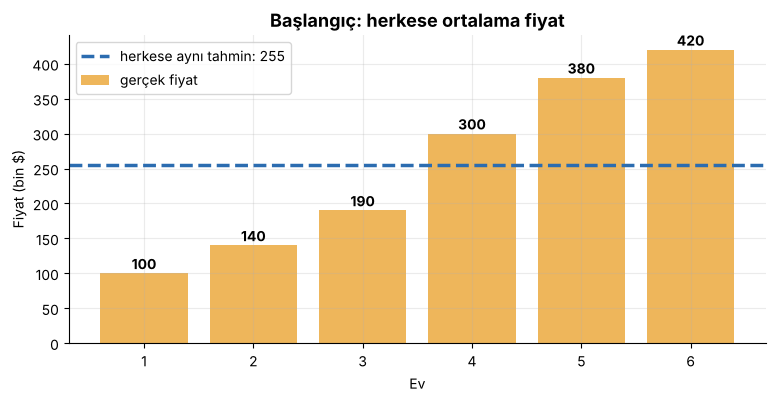

In [4]:
F0 = y_ev.mean()                                    # başlangıç tahmini = fiyatların ortalaması
print(f"Başlangıç tahmini F₀ = ({' + '.join(str(int(v)) for v in y_ev)}) / 6 = {F0:.0f} bin $")
print(f"Bu tahminle ortalama kare hata (RMSE) = {rmse(y_ev, np.full(6, F0)):.1f} bin $")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ev["Ev"], y_ev, color=RENK["altin"], alpha=0.9, label="gerçek fiyat")
ax.axhline(F0, color=RENK["mavi"], ls="--", lw=2.5, label=f"herkese aynı tahmin: {F0:.0f}")
for e, v in zip(ev["Ev"], y_ev):
    ax.text(e, v + 6, f"{v:.0f}", ha="center", fontweight="bold")
ax.set(title="Başlangıç: herkese ortalama fiyat", xlabel="Ev", ylabel="Fiyat (bin $)")
ax.legend()
kaydet(fig, "kavram_03_baslangic_tahmini")
plt.show()

<table><tr><td>

<img src="assets/etiket_kavram.svg" height="34" alt="Kavram">

**Başlangıç tahmini** (ortalama) pahalı evleri **ucuz**, ucuz evleri **pahalı** sanır. Bu hatalar boşa gitmez: bir sonraki çırağın **ders kitabıdır**.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4">
</p>

Ustanın her ev için ne kadar yanıldığına **artık** (*residual*) diyoruz:

$$\text{artık} = \text{gerçek fiyat} - \text{tahmin}$$

- Artık **negatif** → model **fazla pahalı** sandı → tahmini **aşağı** çekmek gerekir.
- Artık **pozitif** → model **ucuz** sandı → tahmini **yukarı** çekmek gerekir.

<p align="center">
  <img src="assets/diyagram_artik.svg" width="100%" alt="Artık nedir">
</p>

,Ev,Gelir (10 bin $),Fiyat (bin $),Tahmin F₀,Artık
0,1,2.0,100,255.0,-155.0
1,2,3.0,140,255.0,-115.0
2,3,4.0,190,255.0,-65.0
3,4,6.0,300,255.0,45.0
4,5,8.0,380,255.0,125.0
5,6,9.0,420,255.0,165.0


💾 Kaydedildi → outputs/figures/kavram_04_artiklar.png


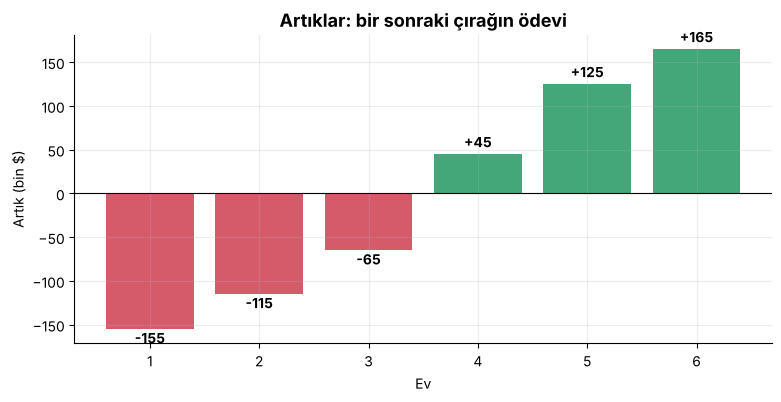

In [5]:
tahmin_0 = np.full(6, F0)
R0 = y_ev - tahmin_0                                 # artıklar: bir sonraki ağacın hedefi
ev["Tahmin F₀"] = tahmin_0
ev["Artık"] = R0
display(ev[["Ev", "Gelir (10 bin $)", "Fiyat (bin $)", "Tahmin F₀", "Artık"]])

fig, ax = plt.subplots(figsize=(9, 4))
renkler = [RENK["pembe"] if r < 0 else RENK["yesil"] for r in R0]
ax.bar(ev["Ev"], R0, color=renkler, alpha=0.9)
for e, r in zip(ev["Ev"], R0):
    ax.text(e, r + (8 if r > 0 else -16), f"{r:+.0f}", ha="center", fontweight="bold")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Artıklar: bir sonraki çırağın ödevi", xlabel="Ev", ylabel="Artık (bin $)")
kaydet(fig, "kavram_04_artiklar")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Bu andan itibaren **yeni ağacın hedefi fiyatın kendisi değil, artıklardır**. Yani çırak “bu evin fiyatı kaç?” diye değil, “**ustanın bu evde yanılma miktarı** ne?” diye sorar. Boosting'in bütün sırrı budur.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5">
</p>

Çırak, artıkları **en iyi ayıran** tek bir soru arar. Örneğin “Gelir ≤ 5 mi?”. Soru, evleri ikiye böler; her grupta artıklar **birbirine benzemelidir** (hepsi negatif ya da hepsi pozitif). Bunu bir **benzerlik skoruyla** ölçeriz:

$$\text{benzerlik} = \frac{(\text{artıkların toplamı})^2}{\text{ev sayısı} + \lambda}$$

Artıklar aynı işaretliyse toplamları büyür, skor yükselir. Bir bölünmenin **kazancı (gain)**, iki çocuğun benzerliklerinin toplamından bölünmeden önceki benzerliği çıkararak bulunur. Şimdilik $\lambda = 1$ (frenin ne olduğunu 8. bölümde göreceğiz).

<p align="center">
  <img src="assets/diyagram_agac_hesabi.svg" width="100%" alt="Ağaç hesabı">
</p>

### 🔎 5.1 · Tüm Aday Soruları Deneyelim

Her özellik için her olası eşiği (komşu değerlerin ortası) deneyip kazancı hesaplıyoruz. **En yüksek kazanç kazanır.**

,Soru,Sol grupta ev,Kazanç
0,Gelir ≤ 5 ?,3,56112.5
1,Gelir ≤ 7 ?,4,44853.3
2,Gelir ≤ 3.5 ?,2,38880.0
3,Sahile uzaklık ≤ 32.5 ?,3,25312.5
4,Gelir ≤ 8.5 ?,5,18150.0
5,Gelir ≤ 2.5 ?,1,16016.7
6,Sahile uzaklık ≤ 17.5 ?,1,10416.7
7,Sahile uzaklık ≤ 47.5 ?,5,8816.7
8,Sahile uzaklık ≤ 37.5 ?,4,2613.3
9,Sahile uzaklık ≤ 27.5 ?,2,1920.0


💾 Kaydedildi → outputs/figures/kavram_05_aday_bolunmeler.png


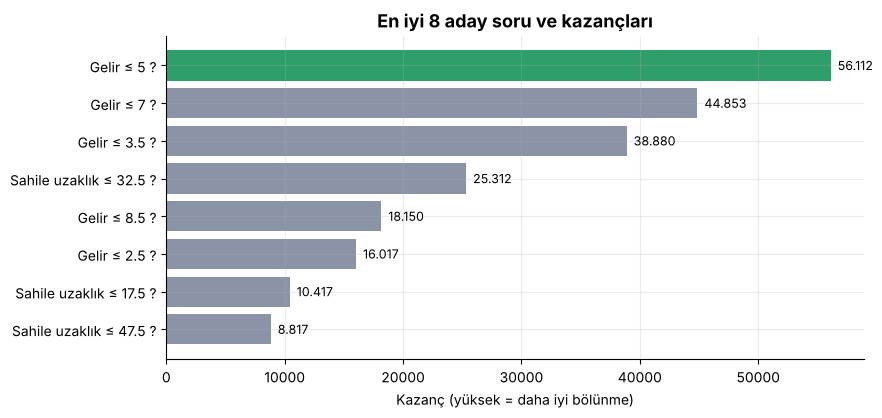

In [6]:
LAM = 1.0                                            # λ: freni şimdilik 1 tutuyoruz


def benzerlik(r, lam=LAM):
    """Bir gruptaki artıkların 'benzerlik' skoru: (toplam)² / (kişi sayısı + λ)."""
    return r.sum() ** 2 / (len(r) + lam)


def bolunme_kazanci(sol_maske, r=R0, lam=LAM):
    """Bölünmenin kazancı = sol benzerlik + sağ benzerlik − bölünmeden önceki benzerlik."""
    return benzerlik(r[sol_maske], lam) + benzerlik(r[~sol_maske], lam) - benzerlik(r, lam)


adaylar = []
for j, ad in enumerate(["Gelir", "Sahile uzaklık"]):
    degerler = np.sort(np.unique(X_ev[:, j]))
    for a, b in zip(degerler[:-1], degerler[1:]):
        esik = (a + b) / 2
        adaylar.append({"Soru": f"{ad} ≤ {esik:g} ?", "Sol grupta ev": int((X_ev[:, j] <= esik).sum()),
                        "Kazanç": bolunme_kazanci(X_ev[:, j] <= esik)})
adaylar = pd.DataFrame(adaylar).sort_values("Kazanç", ascending=False).reset_index(drop=True)
display(adaylar.round(1))

fig, ax = plt.subplots(figsize=(9, 4.2))
ilk = adaylar.head(8).iloc[::-1]
ax.barh(ilk["Soru"], ilk["Kazanç"], color=[RENK["yesil"] if k == adaylar["Kazanç"].max() else RENK["gri"] for k in ilk["Kazanç"]])
for y, k in enumerate(ilk["Kazanç"]):
    ax.text(k + 600, y, f"{k:,.0f}".replace(",", "."), va="center", fontsize=9)
ax.set(title="En iyi 8 aday soru ve kazançları", xlabel="Kazanç (yüksek = daha iyi bölünme)")
kaydet(fig, "kavram_05_aday_bolunmeler")
plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Kazanan soru: “Gelir ≤ 5 mi?”** Üç ucuz evi (artıklar hep negatif) ve üç pahalı evi (artıklar hep pozitif) mükemmel ayırıyor. “Sahile uzaklık” bu küçük tabloda daha az ayırıcı. Yani ağaç, **hangi özelliğe bakacağını kendisi seçiyor**.

</td></tr></table>

### 🎞️ 5.2 · Bölünme Tarayıcısı (Animasyon)

Aşağıdaki animasyonda **eşik çizgisi** gelir ekseninde kayıyor; sağdaki sütunlar o eşiğin **kazancını** gösteriyor. Kazanç tepe noktasına ulaştığında çizgi “doğru yerde” demektir.

💾 Animasyon → outputs/figures/kavram_05_bolunme_tarayici.gif (36 KB)


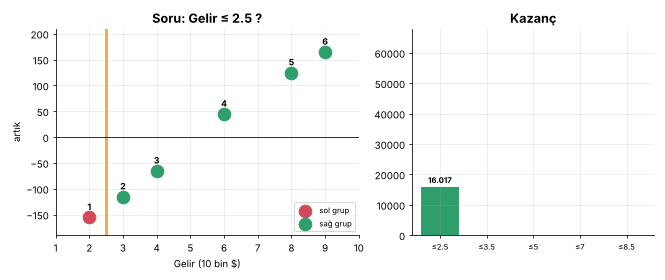

In [7]:
esikler = [2.5, 3.5, 5.0, 7.0, 8.5]
kazanc = {e: bolunme_kazanci(X_ev[:, 0] <= e) for e in esikler}


def kare_bolunme(fig, i):
    fig.clf()
    k = min(i // 2, len(esikler) - 1)                            # her eşikte 2 kare bekle
    esik = esikler[k]
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.25, 1]})
    sol = X_ev[:, 0] <= esik
    ax1.scatter(X_ev[sol, 0], R0[sol], s=170, color=RENK["pembe"], zorder=3, label="sol grup")
    ax1.scatter(X_ev[~sol, 0], R0[~sol], s=170, color=RENK["yesil"], zorder=3, label="sağ grup")
    ax1.axvline(esik, color=RENK["altin"], lw=3)
    ax1.axhline(0, color="black", lw=0.8)
    for xx, rr, e in zip(X_ev[:, 0], R0, ev["Ev"]):
        ax1.text(xx, rr + 14, str(e), ha="center", fontsize=9, fontweight="bold")
    ax1.set(title=f"Soru: Gelir ≤ {esik:g} ?", xlabel="Gelir (10 bin $)", ylabel="artık", ylim=(-190, 210), xlim=(1, 10))
    ax1.legend(loc="lower right", fontsize=8)
    gorulen = esikler[: k + 1]
    en_iyi = max(kazanc[x] for x in gorulen)
    ax2.bar([f"≤{e:g}" for e in gorulen], [kazanc[e] for e in gorulen], color=[RENK["yesil"] if kazanc[e] == en_iyi else RENK["gri"] for e in gorulen])
    for j, e in enumerate(gorulen):
        ax2.text(j, kazanc[e] + 1200, f"{kazanc[e]:,.0f}".replace(",", "."), ha="center", fontweight="bold", fontsize=8)
    ax2.set(title="Kazanç", ylim=(0, 68000), xlim=(-0.6, len(esikler) - 0.4))
    ax2.set_xticks(range(len(esikler)))
    ax2.set_xticklabels([f"≤{e:g}" for e in esikler], fontsize=8)
    fig.tight_layout()


gif_kaydet(kare_bolunme, len(esikler) * 2 + 3, FIG_DIR / "kavram_05_bolunme_tarayici.gif", figsize=(9.5, 4), fps=2)
display(Image(filename=FIG_DIR / "kavram_05_bolunme_tarayici.gif"))

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6">
</p>

Ağaç evleri ikiye böldü. Şimdi **her gruba bir düzeltme sayısı** (yaprak değeri) yazacağız. Kural basit: grubun artıklarının toplamını, grubun büyüklüğüne ($+\lambda$) böl; yani “**grubun ortalama hatası**, biraz frenlenmiş”.

$$\text{yaprak değeri} = \frac{\text{artıkların toplamı}}{\text{ev sayısı} + \lambda}$$

Ama düzeltmenin **tamamını** uygulamayız; **öğrenme hızı (η, eta)** ile küçülterek uygularız:

$$\text{yeni tahmin} = \text{eski tahmin} + \eta \times \text{yaprak değeri}$$

Neden küçük adım? Çünkü tek çırağa fazla güvenmek **ezbere** götürür; çok sayıda küçük düzeltme daha sağlam sonuç verir. Bu bölümde $\eta = 0{,}3$ kullanıyoruz.

### 👣 6.1 · Hesabı Elle Yapalım

In [8]:
ETA = 0.3                                            # η: öğrenme hızı (adım küçültücü)
sol = X_ev[:, 0] <= 5.0                              # kazanan soru: Gelir ≤ 5 ?

yaprak_sol = R0[sol].sum() / (sol.sum() + LAM)       # sol yaprak değeri
yaprak_sag = R0[~sol].sum() / ((~sol).sum() + LAM)   # sağ yaprak değeri
print(f"Sol yaprak  : {R0[sol].sum():+.0f} / ({sol.sum()} + {LAM:g}) = {yaprak_sol:+.2f}")
print(f"Sağ yaprak  : {R0[~sol].sum():+.0f} / ({(~sol).sum()} + {LAM:g}) = {yaprak_sag:+.2f}")

duzeltme = np.where(sol, yaprak_sol, yaprak_sag)     # her evin düştüğü yaprağın değeri
tahmin_1 = tahmin_0 + ETA * duzeltme                 # yeni tahmin = eski + η × yaprak
R1 = y_ev - tahmin_1

tablo = ev[["Ev", "Gelir (10 bin $)", "Fiyat (bin $)"]].copy()
tablo["F₀"] = tahmin_0
tablo["Yaprak"] = duzeltme
tablo["F₁ = F₀ + η·yaprak"] = tahmin_1
tablo["Yeni artık"] = R1
display(tablo.round(2))
print(f"\nRMSE: {rmse(y_ev, tahmin_0):.1f} → {rmse(y_ev, tahmin_1):.1f} bin $  (tek küçük adımla)")

Sol yaprak  : -335 / (3 + 1) = -83.75
Sağ yaprak  : +335 / (3 + 1) = +83.75


,Ev,Gelir (10 bin $),Fiyat (bin $),F₀,Yaprak,F₁ = F₀ + η·yaprak,Yeni artık
0,1,2.0,100,255.0,-83.75,229.88,-129.88
1,2,3.0,140,255.0,-83.75,229.88,-89.88
2,3,4.0,190,255.0,-83.75,229.88,-39.88
3,4,6.0,300,255.0,83.75,280.12,19.88
4,5,8.0,380,255.0,83.75,280.12,99.88
5,6,9.0,420,255.0,83.75,280.12,139.88



RMSE: 120.0 → 97.0 bin $  (tek küçük adımla)


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Tek çırak, tek küçük adım: hata **belirgin biçimde azaldı** ama hâlâ kalan artıklar var. Bunlar **2. çırağın** işi. Her turda aynı üç adımı tekrarlarız: **artığı hesapla → ağaç kur → küçük adımla güncelle.**

</td></tr></table>

### 🔁 6.2 · Döngünün Tamamı

<p align="center">
  <img src="assets/diyagram_dongu.svg" width="100%" alt="Beş adımlık döngü">
</p>

Tur 1: soru = Gelir ≤ 5 ?  → RMSE =   97.0
Tur 2: soru = Gelir ≤ 5 ?  → RMSE =   80.1
Tur 3: soru = Gelir ≤ 7 ?  → RMSE =   67.1
Tur 4: soru = Gelir ≤ 5 ?  → RMSE =   56.8
Tur 5: soru = Gelir ≤ 3.5 ?  → RMSE =   48.7
💾 Kaydedildi → outputs/figures/kavram_06_tur_tur_hata.png


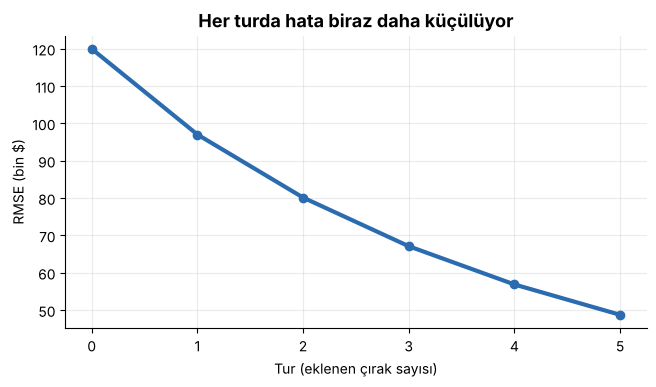

In [9]:
# Aynı hesabı 5 tur boyunca elle tekrar edelim (her turda en iyi bölünmeyi arayıp yaprakları güncelliyoruz)
def en_iyi_agac(r, X, lam=LAM):
    """r artıklarına tek kök bölünmeli (derinlik 1) ağaç kurar; (özellik, eşik, sol_yaprak, sağ_yaprak) döner."""
    en = (-np.inf, None, None)
    for j in range(X.shape[1]):
        v = np.sort(np.unique(X[:, j]))
        for a, b in zip(v[:-1], v[1:]):
            e = (a + b) / 2
            k = benzerlik(r[X[:, j] <= e], lam) + benzerlik(r[X[:, j] > e], lam) - benzerlik(r, lam)
            if k > en[0]:
                en = (k, j, e)
    _, j, e = en
    m = X[:, j] <= e
    return j, e, r[m].sum() / (m.sum() + lam), r[~m].sum() / ((~m).sum() + lam)


tahmin = np.full(6, F0)
gecmis = [rmse(y_ev, tahmin)]
for tur in range(1, 6):
    j, e, vs, vg = en_iyi_agac(y_ev - tahmin, X_ev)
    tahmin = tahmin + ETA * np.where(X_ev[:, j] <= e, vs, vg)
    gecmis.append(rmse(y_ev, tahmin))
    print(f"Tur {tur}: soru = {['Gelir', 'Sahile uzaklık'][j]} ≤ {e:g} ?  → RMSE = {gecmis[-1]:6.1f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(range(6), gecmis, "o-", color=RENK["mavi"], lw=3)
ax.set(title="Her turda hata biraz daha küçülüyor", xlabel="Tur (eklenen çırak sayısı)", ylabel="RMSE (bin $)")
kaydet(fig, "kavram_06_tur_tur_hata")
plt.show()

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7">
</p>

Elle yaptığımız hesabın **gerçek XGBoost ile aynı** olup olmadığını sınayalım. Gerçek kütüphaneye aynı ayarları veriyoruz: **1 ağaç, derinlik 1, η = 0,3, λ = 1, γ = 0**, başlangıç tahmini = ortalama.

### ✅ 7.1 · Gerçek Kütüphane Aynı Şeyi Yapıyor mu?

In [10]:
model_1 = XGBRegressor(n_estimators=1, max_depth=1, learning_rate=ETA, reg_lambda=LAM, gamma=0, min_child_weight=1,
                       base_score=F0, tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(X_ev, y_ev)
xgb_tahmin = model_1.predict(X_ev)

karsilastirma = pd.DataFrame({"Ev": ev["Ev"], "Elle hesap F₁": tahmin_1, "XGBoost": xgb_tahmin})
karsilastirma["Fark"] = karsilastirma["XGBoost"] - karsilastirma["Elle hesap F₁"]
display(karsilastirma.round(4))
print(f"En büyük fark: {np.abs(karsilastirma['Fark']).max():.2e} bin $")

agac = model_1.get_booster().trees_to_dataframe()
display(agac[["Node", "Feature", "Split", "Yes", "No", "Gain", "Cover"]])

,Ev,Elle hesap F₁,XGBoost,Fark
0,1,229.875,229.875,0.0
1,2,229.875,229.875,0.0
2,3,229.875,229.875,0.0
3,4,280.125,280.125,0.0
4,5,280.125,280.125,0.0
5,6,280.125,280.125,0.0


En büyük fark: 0.00e+00 bin $


,Node,Feature,Split,Yes,No,Gain,Cover
0,0,f0,5.0,0-1,0-2,56112.5,6.0
1,1,Leaf,<NA>,<NA>,<NA>,-25.125002,3.0
2,2,Leaf,<NA>,<NA>,<NA>,25.125002,3.0


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle yaptığımız hesap ile `xgboost` kütüphanesi **aynı sayıları** verdi (fark ihmal edilebilir). Ağaç tablosunda kök düğüm **f0 (gelir)** üzerinde **5** eşiğinde bölünüyor; `Gain` sütunu bizim hesapladığımız kazançla aynıdır. Kütüphane bir sihir değil, bildiğimiz hesabın hızlı hâlidir.

</td></tr></table>

### 🎞️ 7.2 · Hata Avcısı (Animasyon)

Şimdi 6 ev yerine **gerçek Kaliforniya mahallelerinden 150 tanesini** alalım. Her turda **üst panel** modelin güncel tahminini, **alt panel** ise yeni ağacın **artıklara** önerdiği düzeltmeyi gösterir. Tahmin eğrisi veriye yaklaştıkça artıklar küçülür.

💾 Animasyon → outputs/figures/kavram_07_hata_avcisi.gif (148 KB)


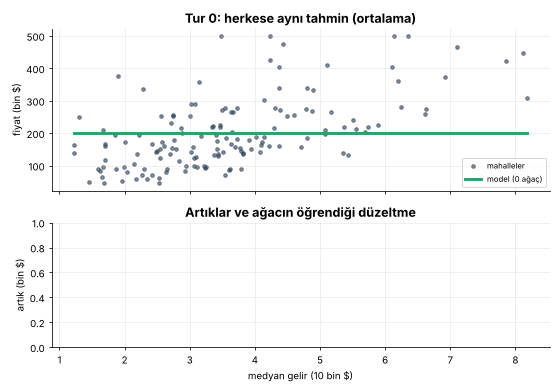

In [11]:
ham = pd.read_csv(VERI_YOLU)
ornek = ham.sample(150, random_state=RANDOM_STATE)
ornek = ornek[ornek["median_income"] < 9].sort_values("median_income")        # çok uç gelirleri çıkar: grafik okunaklı olsun
xr = ornek["median_income"].to_numpy()
yr = ornek["median_house_value"].to_numpy() / 1000                            # bin $
Xr = xr.reshape(-1, 1)
izg = np.linspace(xr.min(), xr.max(), 300).reshape(-1, 1)

av_model = XGBRegressor(n_estimators=12, max_depth=2, learning_rate=0.5, reg_lambda=1, random_state=RANDOM_STATE, n_jobs=1).fit(Xr, yr)
taban = float(np.mean(yr))                                                    # başlangıç = ortalama


def tahmin_k(k, X):
    """İlk k ağaçla yapılan tahmin (k = 0 ise yalnızca başlangıç ortalaması)."""
    return np.full(len(X), taban) if k == 0 else av_model.predict(X, iteration_range=(0, k))


def kare_hata_avcisi(fig, i):
    fig.clf()
    k = min(i, 12)
    ust, alt = fig.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
    ust.scatter(xr, yr, s=14, color=RENK["koyu"], alpha=0.6, label="mahalleler")
    ust.plot(izg, tahmin_k(k, izg), color=RENK["yesil"], lw=3, label=f"model ({k} ağaç)")
    ust.legend(loc="lower right", fontsize=8)
    ust.set_title(f"Tur {k}: güncel tahmin" if k else "Tur 0: herkese aynı tahmin (ortalama)")
    ust.set_ylabel("fiyat (bin $)")
    if k > 0:
        artik = yr - tahmin_k(k - 1, Xr)
        yeni_duzeltme = (tahmin_k(k, izg) - tahmin_k(k - 1, izg)) / 0.5            # η'ya bölerek ağacın ham yaprak değerleri
        alt.scatter(xr, artik, s=14, color=RENK["pembe"], alpha=0.7, label="artık (gerçek − önceki tahmin)")
        alt.step(izg.ravel(), yeni_duzeltme, where="mid", color=RENK["mavi"], lw=3, label="yeni ağacın önerisi")
        alt.axhline(0, color="black", lw=0.7)
        alt.legend(loc="lower right", fontsize=8)
    alt.set(title="Artıklar ve ağacın öğrendiği düzeltme", xlabel="medyan gelir (10 bin $)", ylabel="artık (bin $)")
    fig.tight_layout()


gif_kaydet(kare_hata_avcisi, 16, FIG_DIR / "kavram_07_hata_avcisi.gif", figsize=(8, 5.6), fps=2, dpi=70)
display(Image(filename=FIG_DIR / "kavram_07_hata_avcisi.gif"))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

İlk turlarda model yalnızca **büyük resmi** yakalıyor (kaba basamaklar). Sonraki turlarda **artıklar küçüldükçe** ağaçların önerdiği düzeltmeler de küçülüyor ve eğri inceliyor. Alt paneldeki mavi basamaklar, “**şu bölgede biraz yukarı, şurada biraz aşağı**” diyen çırağın notlarıdır.

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8">
</p>

Bir çırak **aşırı hevesli** olabilir: tek bir garip evi açıklamak için koca bir kural uydurabilir (ezber). XGBoost'ta iki fren vardır:

- **λ (lambda):** yaprak değerini **küçültür**. Paydadaki $+\lambda$ yüzünden düzeltme cılızlaşır.
- **γ (gamma):** bir bölünmenin kazancı γ'dan **küçükse** o bölünmeyi **hiç yapma** (ağacı buda).

<p align="center">
  <img src="assets/diyagram_duzenleme.svg" width="100%" alt="Düzenleme">
</p>

### 🧮 8.1 · λ Yaprak Değerini Nasıl Küçültür?

,λ,yaprak değeri,ilk değere göre
0,0,111.67,%100
1,1,83.75,%75
2,2,67.00,%60
3,5,41.88,%38
4,10,25.77,%23
5,20,14.57,%13


💾 Kaydedildi → outputs/figures/kavram_08_lambda_yaprak.png


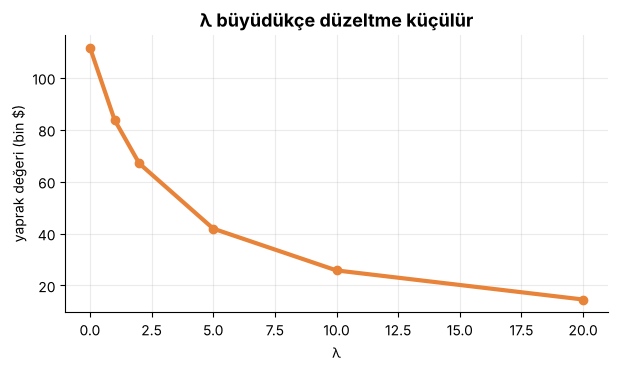

In [12]:
toplam_artik, n_ev = 335.0, 3                                       # sol yaprak: üç ucuz evin artık toplamı (mutlak)
lambdalar = [0, 1, 2, 5, 10, 20]
degerler = [toplam_artik / (n_ev + lam) for lam in lambdalar]
display(pd.DataFrame({"λ": lambdalar, "yaprak değeri": np.round(degerler, 2), "ilk değere göre": [f"%{100 * d / degerler[0]:.0f}" for d in degerler]}))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(lambdalar, degerler, "o-", color=RENK["turuncu"], lw=3)
ax.set(title="λ büyüdükçe düzeltme küçülür", xlabel="λ", ylabel="yaprak değeri (bin $)")
kaydet(fig, "kavram_08_lambda_yaprak")
plt.show()

### ✂️ 8.2 · γ Zayıf Bölünmeyi Reddeder

Kök bölünmenin kazancı yaklaşık **56.113**. γ'yı bunun altında/üstünde seçip gerçek XGBoost'a soralım: ağaç **kaç bölünme** yapıyor?

In [13]:
satirlar = []
for g in [0, 30000, 56000, 57000]:
    m = XGBRegressor(n_estimators=1, max_depth=2, learning_rate=ETA, reg_lambda=LAM, gamma=g, min_child_weight=1,
                     base_score=F0, tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(X_ev, y_ev)
    t = m.get_booster().trees_to_dataframe()
    satirlar.append({"γ": g, "bölünme sayısı": int((t["Feature"] != "Leaf").sum()), "yaprak sayısı": int((t["Feature"] == "Leaf").sum())})
display(pd.DataFrame(satirlar))
print("Kökün gerçek kazancı (kütüphaneden):", round(float(model_1.get_booster().trees_to_dataframe().loc[0, "Gain"]), 1))

,γ,bölünme sayısı,yaprak sayısı
0,0,2,3
1,30000,1,2
2,56000,1,2
3,57000,0,1


Kökün gerçek kazancı (kütüphaneden): 56112.5


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

γ küçükken ağaç **bölünmeye devam eder**; γ kökün kazancını **aştığında** hiç bölünme yapılmaz ve ağaç tek yaprağa iner. Yani γ, “**bu bölünme çabaya değmez**” diyen bir bütçe kontrolcüsüdür.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9">
</p>

Şimdi **gerçek veriye** geçelim: 20.640 Kaliforniya mahallesi. Her satır bir mahalle; hedef **ortanca ev değeri**. Veriyi **eğitim** (modelin çalıştığı) ve **test** (modelin hiç görmediği, sınav) olarak ayırıyoruz. Bu derste ağırlık kavramda olduğu için hazırlık **basit** tutuldu (projede tam bir sızıntısız pipeline kuracağız); `okyanus yakınlığı` yazıdan sayıya çevriliyor ve **boş hücrelere dokunmuyoruz**: XGBoost boşlukları kendi yönetir (12. bölüm).

### 📚 9.1 · Veriyi Tanıyalım

In [14]:
ham = pd.read_csv(VERI_YOLU)
print(f"{ham.shape[0]:,} mahalle · {ham.shape[1]} sütun · boş hücre: {int(ham.isna().sum().sum())} (hepsi total_bedrooms)")
display(ham.head(5))

# okyanus yakınlığını 0/1 sütunlara çevir (satır bazlı işlem: öğrenme gerektirmez, sızıntı yaratmaz)
X_tum = pd.get_dummies(ham.drop(columns="median_house_value"), columns=["ocean_proximity"], dtype=float)
X_tum.columns = X_tum.columns.str.replace("<", "alti_", regex=False).str.replace(" ", "_")   # XGBoost sütun adlarında "<" sevmez
y_tum = ham["median_house_value"] / 1000                                      # bin $
X_egitim, X_test, y_egitim, y_test = train_test_split(X_tum, y_tum, test_size=0.2, random_state=RANDOM_STATE)
X_e, X_v, y_e, y_v = train_test_split(X_egitim, y_egitim, test_size=0.25, random_state=RANDOM_STATE)   # eğitim içinden "deneme sınavı"
print(f"Eğitim: {len(X_e):,} · Deneme sınavı (doğrulama): {len(X_v):,} · Asıl test: {len(X_test):,}")

20,640 mahalle · 10 sütun · boş hücre: 207 (hepsi total_bedrooms)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Eğitim: 12,384 · Deneme sınavı (doğrulama): 4,128 · Asıl test: 4,128


### 🎓 9.2 · Ezber mi, Yetersizlik mi?

Üç ekip kuralım: **sığ** (derinlik 2), **orta** (derinlik 5) ve **çok derin** (derinlik 10) ağaçlı. Hepsini 600 tur eğitip **eğitim hatası** ile **deneme sınavı hatasını** her turda izleyelim.

- İki eğri de **yüksekteyse**: model **yetersiz** (henüz öğrenememiş).
- Eğitim hatası sıfıra inerken sınav hatası **ondan çok uzaksa**: model **ezberlemiş**. Aradaki boşluğa **makas** diyelim.
- Asıl ölçüt her zaman **sınav hatasıdır**.

💾 Kaydedildi → outputs/figures/kavram_09_fazla_ogrenme.png


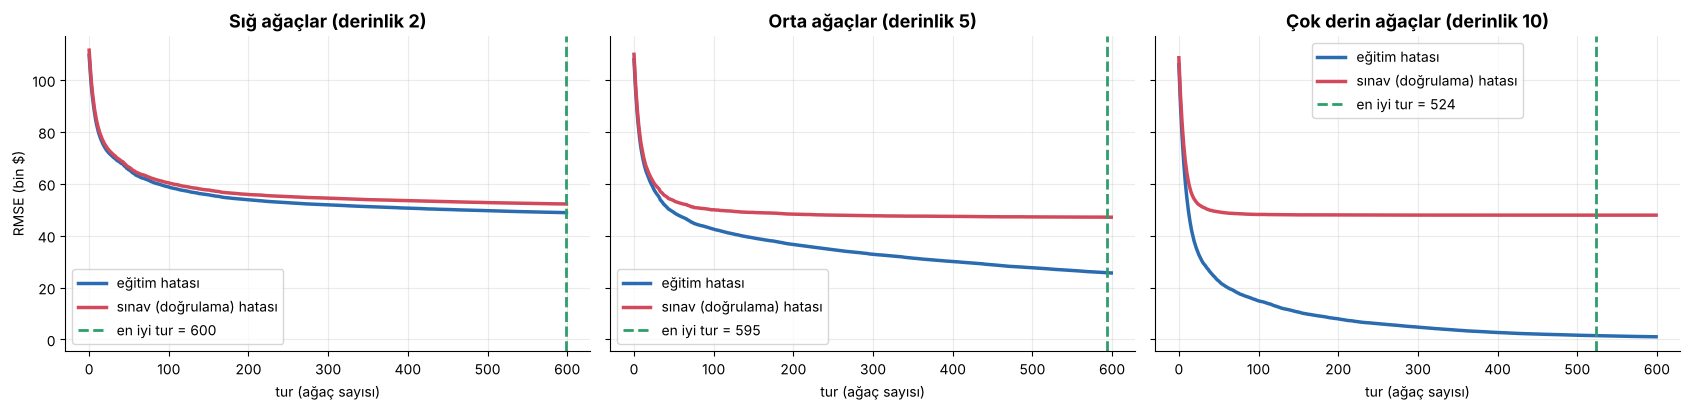

,derinlik,eğitim RMSE,sınav RMSE,makas (sınav − eğitim),en iyi tur
0,2,48.87,52.21,3.34,600
1,5,25.61,47.12,21.51,595
2,10,1.02,47.91,46.89,524


In [15]:
def egri_al(derinlik, tur=600, eta=0.1):
    """Modeli eğitir; her turdaki eğitim ve doğrulama RMSE'sini döndürür."""
    m = XGBRegressor(n_estimators=tur, max_depth=derinlik, learning_rate=eta, eval_metric="rmse", random_state=RANDOM_STATE, n_jobs=4)
    m.fit(X_e, y_e, eval_set=[(X_e, y_e), (X_v, y_v)], verbose=False)
    g = m.evals_result()
    return np.array(g["validation_0"]["rmse"]), np.array(g["validation_1"]["rmse"])


fig, eksen = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
ozet = []
for ax, d, ad in zip(eksen, [2, 5, 10], ["Sığ ağaçlar (derinlik 2)", "Orta ağaçlar (derinlik 5)", "Çok derin ağaçlar (derinlik 10)"]):
    egit, dogr = egri_al(d)
    en_iyi_tur = int(dogr.argmin()) + 1
    ax.plot(egit, color=RENK["mavi"], lw=2.5, label="eğitim hatası")
    ax.plot(dogr, color=RENK["pembe"], lw=2.5, label="sınav (doğrulama) hatası")
    ax.axvline(en_iyi_tur - 1, color=RENK["yesil"], ls="--", lw=2, label=f"en iyi tur = {en_iyi_tur}")
    ax.set(title=ad, xlabel="tur (ağaç sayısı)")
    ax.legend()
    ozet.append({"derinlik": d, "eğitim RMSE": egit[-1], "sınav RMSE": dogr[-1], "makas (sınav − eğitim)": dogr[-1] - egit[-1], "en iyi tur": en_iyi_tur})
eksen[0].set_ylabel("RMSE (bin $)")
fig.tight_layout()
kaydet(fig, "kavram_09_fazla_ogrenme")
plt.show()
display(pd.DataFrame(ozet).round(2))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Sığ ağaçlar** yetersiz kalır: iki eğri de yüksekte, model hâlâ öğrenebilirdi. **Çok derin ağaçlar** eğitim hatasını neredeyse sıfıra indirir (**ezber**, makas çok geniş) ama sınav hatasında **orta derinliği geçemez**. **Orta derinlik** hem makası makul tutar hem en iyi sınav sonucunu verir. Dersin kuralı: **eğitim skoruna değil, sınav skoruna güvenin.**

</td></tr></table>

### ⏱️ 9.3 · Erken Durdurma: Ne Zaman Bırakmalı?

Sınav hatası bir süre iyileşmediğinde eğitimi **otomatik durdurmak** mümkün: buna **erken durdurma** (*early stopping*) denir. “Sınav hatası 50 tur boyunca düzelmediyse dur” diyoruz; model kendi en iyi tur sayısını **kendisi bulur**.

In [16]:
erken = XGBRegressor(n_estimators=3000, max_depth=4, learning_rate=0.05, early_stopping_rounds=50, eval_metric="rmse",
                     random_state=RANDOM_STATE, n_jobs=4)
erken.fit(X_e, y_e, eval_set=[(X_v, y_v)], verbose=False)
print(f"En fazla 3000 tur izin verdik; model {erken.best_iteration + 1} turda en iyi sonucu buldu ve durdu.")
print(f"Sınav RMSE = {erken.best_score:.1f} bin $")

En fazla 3000 tur izin verdik; model 1209 turda en iyi sonucu buldu ve durdu.
Sınav RMSE = 47.8 bin $


<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10">
</p>

Şimdi dersin en güzel kısmı: ekibin **Kaliforniya haritasını** tur tur nasıl çizdiğini izleyelim. Her nokta test setinden bir mahalle; renk **tahmin edilen fiyat**. Soldaki harita **gerçek** fiyatlar, sağdaki **modelin** tahmini.

- **Tur 0:** herkese aynı renk (ortalama).
- İlk ağaçlar **büyük resmi** çizer: sahil pahalı, iç kesim ucuz.
- Sonraki ağaçlar **ayrıntıları** ekler: Bay Area ve Los Angeles'ın pahalı çekirdekleri.

### 🗺️ 10.1 · Haritayı Tur Tur İzleyelim

💾 Animasyon → outputs/figures/kavram_10_harita.gif (328 KB)


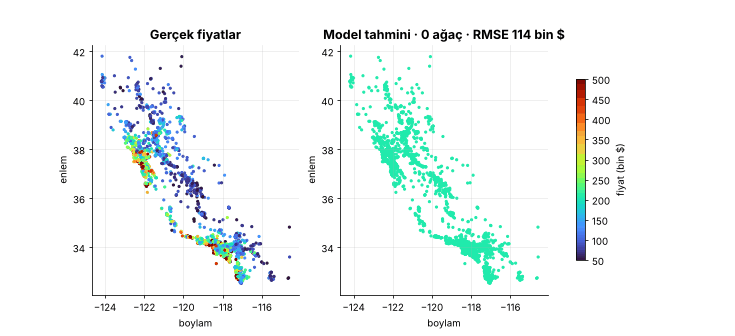

In [17]:
harita_model = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=4).fit(X_egitim, y_egitim)
turlar = [0, 1, 2, 3, 5, 8, 12, 20, 35, 60, 100, 180, 300]
vmin, vmax = 50, 500                                                          # renk ölçeği (bin $)


def harita_tahmini(k):
    """İlk k ağaçla test mahallelerinin tahmini (k=0: yalnızca ortalama)."""
    return np.full(len(X_test), y_egitim.mean()) if k == 0 else harita_model.predict(X_test, iteration_range=(0, k))


def harita_ciz(ax, deger, baslik):
    sc = ax.scatter(X_test["longitude"], X_test["latitude"], c=np.clip(deger, vmin, vmax), s=5, cmap="turbo", vmin=vmin, vmax=vmax)
    ax.set(title=baslik, xlabel="boylam", ylabel="enlem")
    ax.set_aspect(1.25)
    return sc


def kare_harita(fig, i):
    fig.clf()
    k = turlar[min(i, len(turlar) - 1)]
    a1, a2 = fig.subplots(1, 2)
    harita_ciz(a1, y_test.to_numpy(), "Gerçek fiyatlar")
    sc = harita_ciz(a2, harita_tahmini(k), f"Model tahmini · {k} ağaç · RMSE {rmse(y_test, harita_tahmini(k)):.0f} bin $")
    fig.colorbar(sc, ax=[a1, a2], shrink=0.7, label="fiyat (bin $)")


gif_kaydet(kare_harita, len(turlar) + 2, FIG_DIR / "kavram_10_harita.gif", figsize=(10.5, 4.8), fps=2, dpi=70)
display(Image(filename=FIG_DIR / "kavram_10_harita.gif"))

### 🖼️ 10.2 · Dört Kare Yan Yana

Animasyonun dört önemli karesi: **1, 5, 20 ve 300 ağaç**.

💾 Kaydedildi → outputs/figures/kavram_10_harita_dort_kare.png


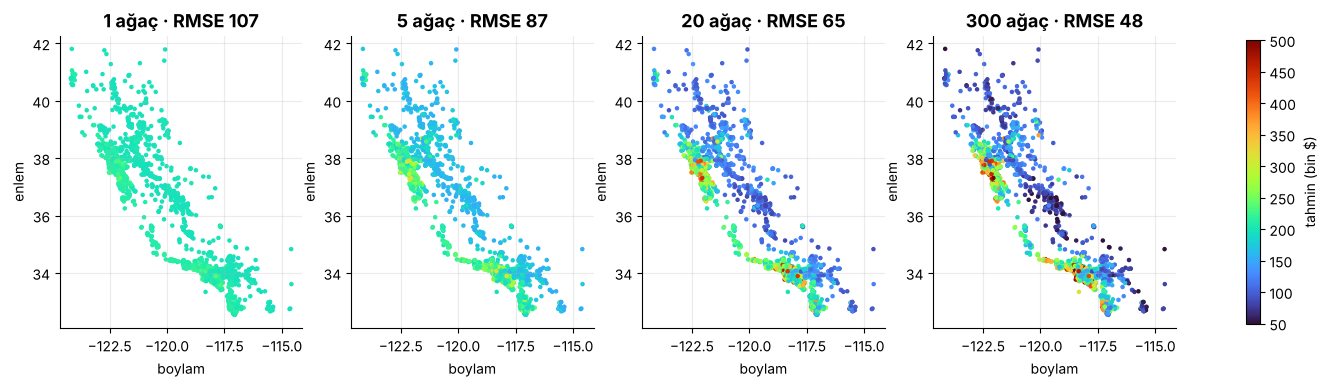

In [18]:
fig, eksen = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, k in zip(eksen, [1, 5, 20, 300]):
    sc = harita_ciz(ax, harita_tahmini(k), f"{k} ağaç · RMSE {rmse(y_test, harita_tahmini(k)):.0f}")
fig.colorbar(sc, ax=eksen, shrink=0.8, label="tahmin (bin $)")
kaydet(fig, "kavram_10_harita_dort_kare")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**1 ağaç** haritayı yalnızca birkaç büyük bloğa böler; **20 ağaçta** kıyı şeridi ve şehirler belirir; **300 ağaçta** tablo, gerçek haritaya çok yakındır. RMSE rakamı da turlarla birlikte düşer. Her çırak haritaya **bir parça** ekler: gelir, konum ve sahile yakınlık gibi ipuçlarını birleştirerek.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11">
</p>

Doğrusal regresyon veriye **tek bir düz çizgi** uydurur. XGBoost ise **basamaklı** bir fonksiyon çizer. Hangisi gerçeğe daha uygun? Gelir ile fiyat arasındaki ilişkiye bakalım. Üstelik fiyatlarda gizli bir tuzak var: veri setinde fiyatlar **500.001 $**'da **kesilmiş** (tavan).

### 📈 11.1 · Gelir ve Fiyat

💾 Kaydedildi → outputs/figures/kavram_11_cizgi_mi_basamak_mi.png


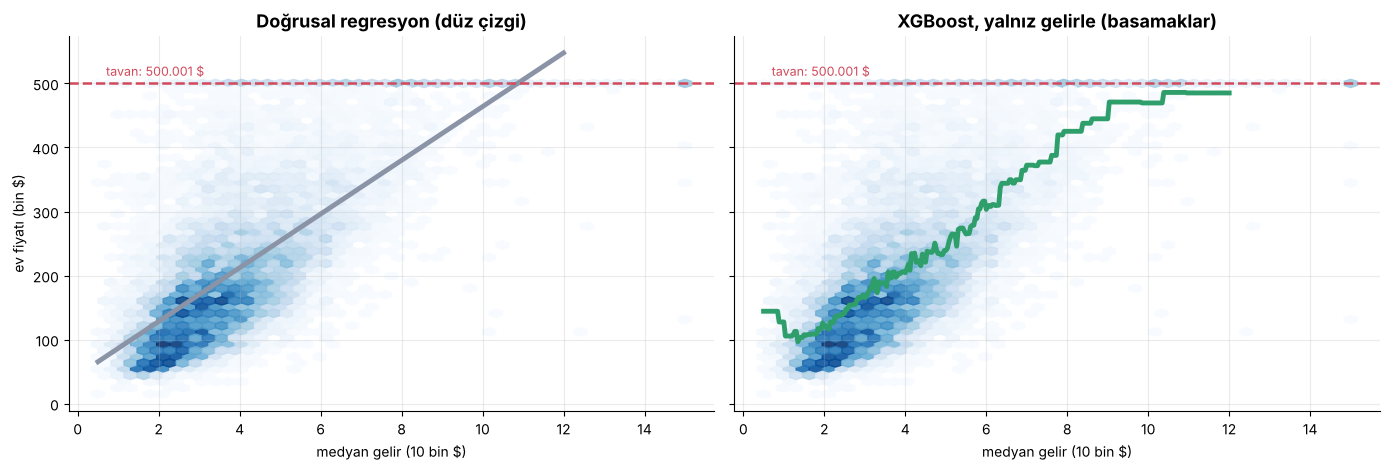

,Model,Test RMSE (bin $)
0,Doğrusal · yalnız gelir,84.2
1,XGBoost · yalnız gelir,83.3
2,XGBoost · tüm özellikler,47.9


In [19]:
g_egitim, g_test = X_egitim[["median_income"]], X_test[["median_income"]]
dogrusal = LinearRegression().fit(g_egitim, y_egitim)
agac_g = XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=4).fit(g_egitim, y_egitim)
xgb_tum = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=4).fit(X_egitim, y_egitim)

gizgi = np.linspace(0.5, 12, 300).reshape(-1, 1)
fig, eksen = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, model, ad, renk in zip(eksen, [dogrusal, agac_g], ["Doğrusal regresyon (düz çizgi)", "XGBoost, yalnız gelirle (basamaklar)"], [RENK["gri"], RENK["yesil"]]):
    ax.hexbin(g_egitim["median_income"], y_egitim, gridsize=45, cmap="Blues", mincnt=1, alpha=0.9)
    ax.plot(gizgi, model.predict(pd.DataFrame(gizgi, columns=["median_income"])), color=renk, lw=3.5)
    ax.axhline(500, color=RENK["pembe"], ls="--", lw=1.8)
    ax.text(0.7, 512, "tavan: 500.001 $", color=RENK["pembe"], fontsize=9)
    ax.set(title=ad, xlabel="medyan gelir (10 bin $)")
eksen[0].set_ylabel("ev fiyatı (bin $)")
fig.tight_layout()
kaydet(fig, "kavram_11_cizgi_mi_basamak_mi")
plt.show()

sonuc = pd.DataFrame({"Model": ["Doğrusal · yalnız gelir", "XGBoost · yalnız gelir", "XGBoost · tüm özellikler"],
                      "Test RMSE (bin $)": [rmse(y_test, dogrusal.predict(g_test)), rmse(y_test, agac_g.predict(g_test)), rmse(y_test, xgb_tum.predict(X_test))]})
display(sonuc.round(1))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Şekil farkı net: düz çizgi yüksek gelirlerde fiyatı **tavanın üzerine** taşırır; basamaklı XGBoost ise **tavanda yatay** kalır. Ama tabloya bakın: **yalnız gelirle** iki modelin hatası neredeyse **aynı**. Çünkü kalan hatanın büyük kısmı gelirle açıklanamayan şeylerden (konum, mahalle özellikleri) gelir. Asıl sıçrama **tüm özelliklerle** olur: ağaç ekibi **etkileşimleri** (“gelirli *ve* sahile yakın”) kendiliğinden öğrenir.

</td></tr></table>

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Tavan değerleri (500.001 $) **gerçek fiyat değil**, “en az bu kadar” anlamına gelir. Hiçbir model tavanın ötesini bilemez; projede bu satırlarla ne yapacağımıza **deneyle** karar vereceğiz.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12">
</p>

XGBoost adındaki **extreme** yalnızca “aşırı güçlü” demek değil, **mühendislik** demektir: bölünmeleri **histogram** yöntemiyle hızlı bulur, çekirdekleri paralel kullanır ve **boş hücreyle** başa çıkar (Chen ve Guestrin, 2016).

<p align="center">
  <img src="assets/diyagram_xgb_farklari.svg" width="100%" alt="XGBoost'un farkları">
</p>

### ⚡ 12.1 · Hız: Aynı Ayar, İki Kütüphane

In [20]:
ortak = dict(n_estimators=300, max_depth=4, learning_rate=0.1, random_state=RANDOM_STATE)
X_dolu = X_egitim.fillna(X_egitim.median())                                    # sklearn GradientBoosting boş hücre kabul etmez

t0 = time.perf_counter(); gb = GradientBoostingRegressor(**ortak).fit(X_dolu, y_egitim); sure_gb = time.perf_counter() - t0
t0 = time.perf_counter(); xg = XGBRegressor(**ortak, n_jobs=4).fit(X_egitim, y_egitim); sure_xgb = time.perf_counter() - t0

hiz = pd.DataFrame({"Model": ["scikit-learn GradientBoosting", "XGBoost"], "Eğitim süresi (sn)": [sure_gb, sure_xgb],
                    "Test RMSE (bin $)": [rmse(y_test, gb.predict(X_test.fillna(X_egitim.median()))), rmse(y_test, xg.predict(X_test))]})
display(hiz.round(2))
print(f"XGBoost yaklaşık {sure_gb / sure_xgb:.0f} kat daha hızlı (süreler makineye bağlıdır).")

,Model,Eğitim süresi (sn),Test RMSE (bin $)
0,scikit-learn GradientBoosting,10.94,48.67
1,XGBoost,0.22,48.03


XGBoost yaklaşık 51 kat daha hızlı (süreler makineye bağlıdır).


### 🕳️ 12.2 · Eksik Veri: Boşluğa Yön Bulmak

Gerçek hayatta tabloların hücreleri boştur. Klasik yaklaşım boşluğu **ortalama/medyanla doldurmaktır**. XGBoost ise her bölünmede boş değerler için “**sola mı, sağa mı?**” sorusunu **veriden öğrenir**. Deneyelim: üç önemli sütunda hücrelerin **%20'sini rastgele silelim**.

,Durum,Test RMSE (bin $)
0,Eksik yok (referans),47.9
1,%20 eksik · XGBoost yönetir,48.9
2,%20 eksik · medyanla doldurulmuş,49.5


💾 Kaydedildi → outputs/figures/kavram_12_eksik_veri.png


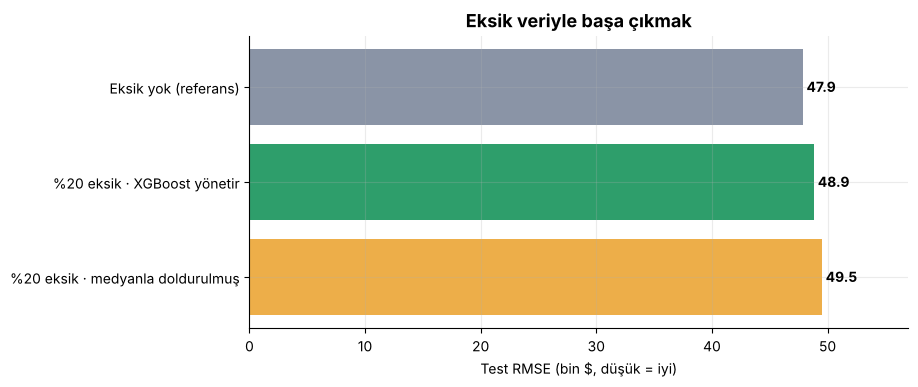

In [21]:
rng = np.random.default_rng(RANDOM_STATE)
X_egitim_bos, X_test_bos = X_egitim.copy(), X_test.copy()
for sutun in ["median_income", "housing_median_age", "total_rooms"]:
    X_egitim_bos.loc[rng.random(len(X_egitim_bos)) < 0.20, sutun] = np.nan
    X_test_bos.loc[rng.random(len(X_test_bos)) < 0.20, sutun] = np.nan

taban_model = dict(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=4)
m_tam = XGBRegressor(**taban_model).fit(X_egitim, y_egitim)                                           # eksik yok
m_bos = XGBRegressor(**taban_model).fit(X_egitim_bos, y_egitim)                                       # XGBoost boşluğu kendi yönetir
med = X_egitim_bos.median()
m_doldur = XGBRegressor(**taban_model).fit(X_egitim_bos.fillna(med), y_egitim)                        # medyanla doldurulmuş

sonuc = pd.DataFrame({"Durum": ["Eksik yok (referans)", "%20 eksik · XGBoost yönetir", "%20 eksik · medyanla doldurulmuş"],
                      "Test RMSE (bin $)": [rmse(y_test, m_tam.predict(X_test)), rmse(y_test, m_bos.predict(X_test_bos)),
                                            rmse(y_test, m_doldur.predict(X_test_bos.fillna(med)))]})
display(sonuc.round(1))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.barh(sonuc["Durum"].iloc[::-1], sonuc["Test RMSE (bin $)"].iloc[::-1], color=[RENK["altin"], RENK["yesil"], RENK["gri"]])
for y, v in enumerate(sonuc["Test RMSE (bin $)"].iloc[::-1]):
    ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontweight="bold")
ax.set(title="Eksik veriyle başa çıkmak", xlabel="Test RMSE (bin $, düşük = iyi)", xlim=(0, sonuc["Test RMSE (bin $)"].max() * 1.15))
kaydet(fig, "kavram_12_eksik_veri")
plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Süreler makineye bağlıdır (XGBoost burada 4 çekirdek ve histogram yöntemi kullanıyor; scikit-learn'ün klasik GradientBoosting'i tek çekirdek ve kesin arama yapıyor); önemli olan **büyüklük mertebesi**: aynı ayarla XGBoost çok daha hızlıdır. Eksik veri deneyinde ise **boşluğu doldurmak her zaman şart değildir**; XGBoost'un öğrendiği yönler çoğu durumda medyan doldurmaya **yakın ya da daha iyi** sonuç verir. (Projede bunu gerçek `total_bedrooms` boşlukları için ayrıca sınayacağız.)

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/kavram_13.svg" width="100%" alt="Bölüm 13">
</p>

Model “bu mahalle pahalı” dediğinde **neye bakıyor**? İki farklı soru var:

1. 🌍 **Genel:** model tüm mahalleler için en çok hangi sütunlara dayanıyor? (*özellik önemi*)
2. 🔦 **Tek bir mahalle için:** bu tahmin **neden** 450 bin $ çıktı? (*SHAP'in sezgisi*)

İkinci soruya **TreeSHAP** (Lundberg vd., 2020) cevap verir: tahmini, her özelliğin **artı veya eksi katkısına** ayırır. XGBoost bunu `pred_contribs=True` ile kendi içinde hesaplar.

### 🧭 13.1 · Genel Önem ve Tek Mahalle Açıklaması

💾 Kaydedildi → outputs/figures/kavram_13_onem_ve_tek_mahalle.png


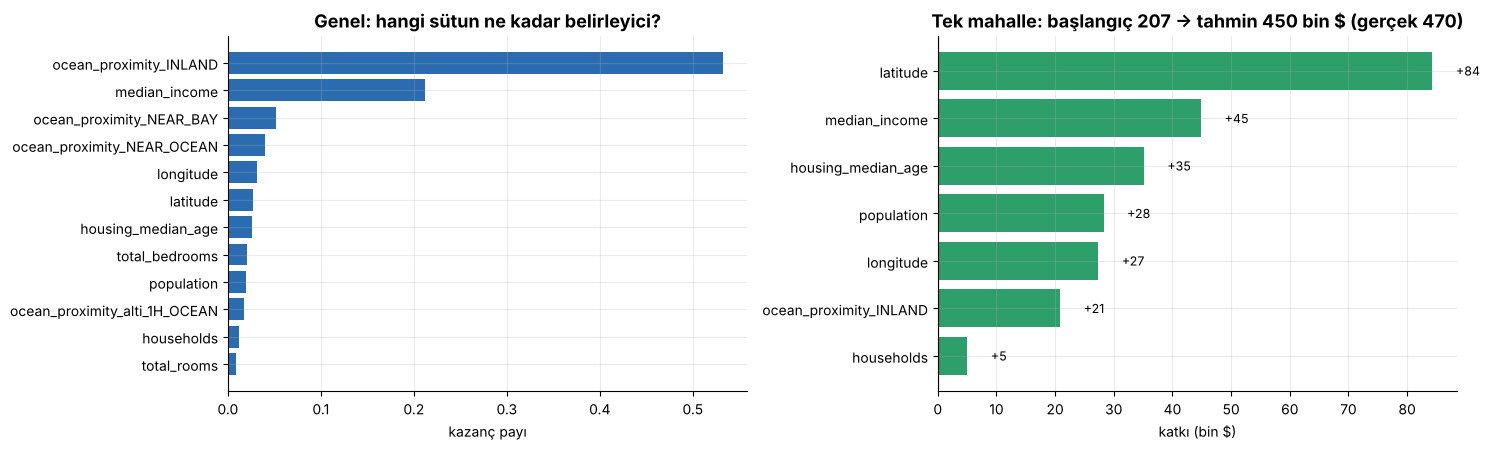

Bu mahalle: gelir 5.1 (10 bin $) · enlem 34.06 · boylam -118.37 · yaş 52


In [22]:
# Genel önem: her sütunun kazanca (gain) toplam katkısı
onem = pd.Series(xgb_tum.get_booster().get_score(importance_type="gain")).sort_values()
onem = onem / onem.sum()

# Tek mahalle: test setinde tahmini yüksek, gerçek fiyatı da yüksek bir örnek seç
tahmin_test = xgb_tum.predict(X_test)
sec = int(np.argsort(np.abs(tahmin_test - 450))[0])                          # tahmini ≈ 450 bin $ olan mahalle
katki = xgb_tum.get_booster().predict(DMatrix(X_test.iloc[[sec]]), pred_contribs=True)[0]
ad_listesi = list(X_test.columns) + ["başlangıç (ortalama)"]
katki = pd.Series(katki, index=ad_listesi)
baslangic = katki.pop("başlangıç (ortalama)")
katki = katki.reindex(katki.abs().sort_values(ascending=False).index)[:7].iloc[::-1]

fig, eksen = plt.subplots(1, 2, figsize=(15, 4.6))
eksen[0].barh(onem.index, onem.values, color=RENK["mavi"])
eksen[0].set(title="Genel: hangi sütun ne kadar belirleyici?", xlabel="kazanç payı")
eksen[1].barh(katki.index, katki.values, color=[RENK["yesil"] if v > 0 else RENK["pembe"] for v in katki.values])
for y, v in enumerate(katki.values):
    eksen[1].text(v + (4 if v > 0 else -4), y, f"{v:+.0f}", va="center", ha="left" if v > 0 else "right", fontsize=9)
eksen[1].axvline(0, color="black", lw=0.8)
eksen[1].set(title=f"Tek mahalle: başlangıç {baslangic:.0f} → tahmin {tahmin_test[sec]:.0f} bin $ (gerçek {y_test.iloc[sec]:.0f})", xlabel="katkı (bin $)")
fig.tight_layout()
kaydet(fig, "kavram_13_onem_ve_tek_mahalle")
plt.show()
satir = X_test.iloc[sec]
print(f"Bu mahalle: gelir {satir['median_income']:.1f} (10 bin $) · enlem {satir['latitude']:.2f} · boylam {satir['longitude']:.2f} · yaş {satir['housing_median_age']:.0f}")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Genel resimde **konum** (iç bölge mi, kıyı mı, hangi koordinat) ve **medyan gelir** öne çıkar; ev fiyatı sezgimizle uyumludur. Sağdaki grafik **bir mahalleyi** açıklar: başlangıç ortalamasından yukarı iten özellikler **yeşil**, aşağı çekenler **kırmızı** görünür (bu mahallede hepsi yukarı itiyor: sahile yakın, yüksek gelirli, şehir merkezi); başlangıç değeri ile bütün katkıların toplamı modelin tahminini verir.

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/kavram_14.svg" width="100%" alt="Bölüm 14">
</p>

Bir şeyi **gerçekten** anladığınızı en iyi, onu **sıfırdan yazarak** anlarsınız. Aşağıdaki sınıf, bu derste elle yaptığımız her adımı (başlangıç ortalaması → artıklar → en iyi bölünme → frenli yaprak değeri → η ile güncelleme) **yaklaşık 40 satırda** yapıyor.

### 🔧 14.1 · Mini XGBoost Regresörü

In [23]:
class MiniXGBRegresor:
    """Öğrenmek için yazılmış mini XGBoost (kareli hata, kesin/exact bölünme araması)."""

    def __init__(self, n_tur=30, derinlik=3, eta=0.3, lam=1.0, gamma=0.0, min_cocuk=1):
        self.n_tur, self.derinlik, self.eta, self.lam, self.gamma, self.min_cocuk = n_tur, derinlik, eta, lam, gamma, min_cocuk

    def _agac(self, X, r, d):
        n = len(r)
        yaprak = r.sum() / (n + self.lam)                                    # yaprak değeri = Σartık / (n + λ)
        if d == 0 or n < 2 * self.min_cocuk:
            return ("yaprak", yaprak)
        S0, en = r.sum() ** 2 / (n + self.lam), None
        for j in range(X.shape[1]):                                          # her sütun için tüm eşikleri tek hamlede tara
            sira = np.argsort(X[:, j], kind="stable")
            xs, cs = X[sira, j], np.cumsum(r[sira])
            nl = np.arange(1, n)
            GL, GR = cs[:-1], cs[-1] - cs[:-1]
            kazanc = GL ** 2 / (nl + self.lam) + GR ** 2 / (n - nl + self.lam) - S0
            gecerli = (xs[:-1] != xs[1:]) & (nl >= self.min_cocuk) & (n - nl >= self.min_cocuk)
            if gecerli.any():
                i = int(np.argmax(np.where(gecerli, kazanc, -np.inf)))
                if en is None or kazanc[i] > en[0]:
                    en = (kazanc[i], j, (xs[i] + xs[i + 1]) / 2)
        if en is None or en[0] < self.gamma:                                 # γ freni: kazanç yetmezse bölme
            return ("yaprak", yaprak)
        _, j, esik = en
        m = X[:, j] < esik
        return ("dugum", j, esik, self._agac(X[m], r[m], d - 1), self._agac(X[~m], r[~m], d - 1))

    def _tahmin(self, agac, x):
        while agac[0] == "dugum":
            agac = agac[3] if x[agac[1]] < agac[2] else agac[4]
        return agac[1]

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.F0, self.agaclar = y.mean(), []
        F = np.full(len(y), self.F0)
        for _ in range(self.n_tur):
            agac = self._agac(X, y - F, self.derinlik)                       # artıklara ağaç kur
            F = F + self.eta * np.array([self._tahmin(agac, x) for x in X])  # küçük adımla güncelle
            self.agaclar.append(agac)
        return self

    def predict(self, X):
        X = np.asarray(X, float)
        return self.F0 + self.eta * sum(np.array([self._tahmin(a, x) for x in X]) for a in self.agaclar)


# Sınav 1: altı evlik örnek (1 ağaç, derinlik 1) — elle hesap, mini model ve gerçek XGBoost üçü bir arada
mini_6 = MiniXGBRegresor(n_tur=1, derinlik=1, eta=ETA, lam=LAM).fit(X_ev, y_ev)
print("Mini XGBoost :", np.round(mini_6.predict(X_ev), 3))
print("Elle hesap   :", np.round(tahmin_1, 3))
print("Gerçek XGB   :", np.round(xgb_tahmin, 3))

Mini XGBoost : [229.875 229.875 229.875 280.125 280.125 280.125]
Elle hesap   : [229.875 229.875 229.875 280.125 280.125 280.125]
Gerçek XGB   : [229.875 229.875 229.875 280.125 280.125 280.125]


### ✅ 14.2 · Gerçek Veride Sınav

Mini modeli **2.000 gerçek mahallede** (derinlik 3, 30 tur) eğitelim ve aynı ayarlı gerçek XGBoost ile **mahalle mahalle** karşılaştıralım.

Mini model 0.3 sn · en büyük fark 0.0001 bin $ · ortalama fark 0.00002 bin $
Eğitim RMSE → mini: 47.79 · gerçek XGBoost: 47.79


💾 Kaydedildi → outputs/figures/kavram_14_mini_xgboost_dogrulama.png


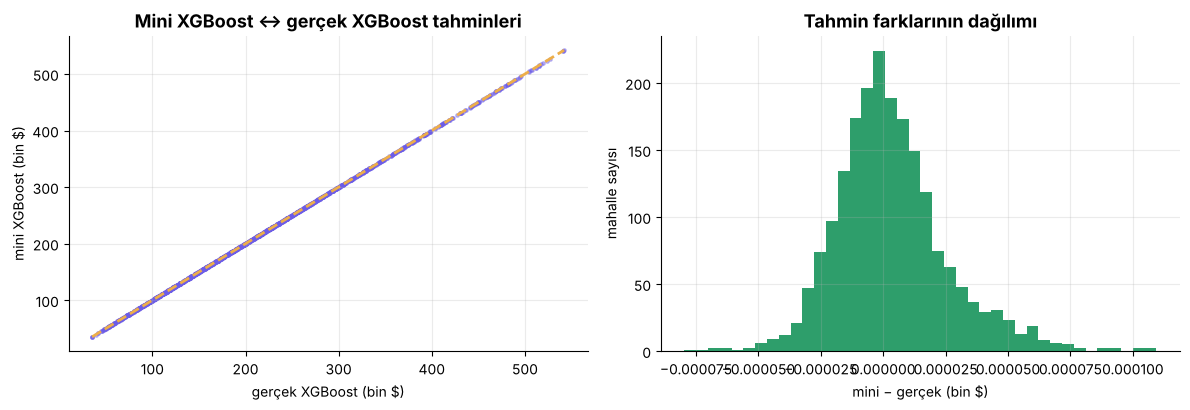

In [24]:
Xs = X_egitim.fillna(X_egitim.median()).iloc[:2000]                           # mini modelimiz boş hücre bilmez: basit doldurma
ys = y_egitim.iloc[:2000]
t0 = time.perf_counter(); mini = MiniXGBRegresor(n_tur=30, derinlik=3, eta=0.3, lam=1.0).fit(Xs.to_numpy(), ys.to_numpy()); sure_mini = time.perf_counter() - t0
gercek = XGBRegressor(n_estimators=30, max_depth=3, learning_rate=0.3, reg_lambda=1.0, gamma=0, min_child_weight=1, base_score=float(ys.mean()),
                      tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(Xs, ys)

p_mini, p_gercek = mini.predict(Xs.to_numpy()), gercek.predict(Xs)
fark = np.abs(p_mini - p_gercek)
print(f"Mini model {sure_mini:.1f} sn · en büyük fark {fark.max():.4f} bin $ · ortalama fark {fark.mean():.5f} bin $")
print(f"Eğitim RMSE → mini: {rmse(ys, p_mini):.2f} · gerçek XGBoost: {rmse(ys, p_gercek):.2f}")

fig, eksen = plt.subplots(1, 2, figsize=(12, 4.2))
eksen[0].scatter(p_gercek, p_mini, s=6, alpha=0.4, color=RENK["mor"])
alt, ust = min(p_gercek.min(), p_mini.min()), max(p_gercek.max(), p_mini.max())
eksen[0].plot([alt, ust], [alt, ust], "--", color=RENK["altin"], lw=2)
eksen[0].set(title="Mini XGBoost ↔ gerçek XGBoost tahminleri", xlabel="gerçek XGBoost (bin $)", ylabel="mini XGBoost (bin $)")
eksen[1].hist(p_mini - p_gercek, bins=40, color=RENK["yesil"])
eksen[1].set(title="Tahmin farklarının dağılımı", xlabel="mini − gerçek (bin $)", ylabel="mahalle sayısı")
fig.tight_layout()
kaydet(fig, "kavram_14_mini_xgboost_dogrulama")
plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle yazdığımız mini model, kütüphane ile **aynı tahminleri** verdi; noktalar 45° çizgisinin üzerinde, farklar yalnızca **ondalık yuvarlama** düzeyinde. XGBoost bir **kara kutu değil**: *artık → en iyi bölünme → frenli yaprak → küçük adım* döngüsünün çok hızlı, çok iyi mühendislenmiş hâlidir.

</td></tr></table>

<a id="p15"></a>

<p align="center">
  <img src="assets/kavram_15.svg" width="100%" alt="Bölüm 15">
</p>

### 🧠 15.1 · Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🎯</h3><b>Ortalamayla başla</b><br><sub><i>F₀ = fiyatların ortalaması</i></sub><br><br>Regresyonda model önce herkese aynı sayıyı, yani ortalamayı söyler<br><br></td><td width="33%" valign="top" align="center"><h3>🩹</h3><b>Artıklara ağaç kur</b><br><sub><i>artık = gerçek − tahmin</i></sub><br><br>Her yeni ağaç fiyatı değil, <b>kalan hatayı</b> öğrenir<br><br></td><td width="33%" valign="top" align="center"><h3>👣</h3><b>Küçük adımlar</b><br><sub><i>η (eta)</i></sub><br><br>Düzeltmenin yalnızca bir kısmı uygulanır; çok ağaç + küçük η güvenli yoldur<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>İki fren</b><br><sub><i>λ ve γ</i></sub><br><br>λ düzeltmeyi küçültür, γ zayıf bölünmeyi reddeder; ezber azalır<br><br></td><td width="33%" valign="top" align="center"><h3>🎓</h3><b>Sınava güven</b><br><sub><i>erken durdurma</i></sub><br><br>Eğitim hatası aldatır; sınav hatası yükselmeye başlayınca dur<br><br></td><td width="33%" valign="top" align="center"><h3>🔧</h3><b>Kara kutu değil</b><br><sub><i>mini XGBoost</i></sub><br><br>40 satırlık model, kütüphaneyle aynı tahminleri verdi<br><br></td></tr>
</table>

### 🆚 15.2 · Sınıflandırma ve Regresyon Arasındaki Fark (Gün 49 ile Köprü)

| | **Sınıflandırma (Gün 49)** | **Regresyon (bu ders)** |
|:--|:--|:--|
| Hedef | Sınıf (yıldız / galaksi / kuasar) | Sayı (ev fiyatı) |
| Başlangıç tahmini | Sınıf oranından **log-odds** | Hedefin **ortalaması** |
| Artık | Gerçek − olasılık | Gerçek − tahmin |
| Yaprak değeri | Artık toplamı ÷ ($\sum p(1-p) + \lambda$) | Artık toplamı ÷ (ev sayısı $+ \lambda$) |
| Son adım | **Sigmoid** ile olasılık | Doğrudan sayı |
| Ölçüt | Doğruluk, F1, log-loss | **RMSE**, MAE, R² |

Derin öğrenme yöntemleriyle yapılan geniş kıyaslamalarda ağaç tabanlı modeller, orta büyüklükteki tablo verilerinde hâlâ çok rekabetçidir (Grinsztajn vd., 2022); ayrıca birçok veri setinde modeller arası fark küçüktür ve **hafif bir ayar**, algoritma seçiminden daha çok işe yarayabilir (McElfresh vd., 2023). Bu yüzden XGBoost, tablo verisinde hâlâ ilk denenen modellerden biridir.

### ❓ 15.3 · Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Altı evin fiyatları 100, 140, 190, 300, 380, 420 ise XGBoost'un başlangıç tahmini nedir?</summary>

Ortalama: $(100+140+190+300+380+420)/6 = 255$ bin $.
</details>

<details><summary><b>2.</b> Artığı −155 olan bir ev için model ne yapmıştır?</summary>

Gerçek fiyatın **155 bin $ üzerinde** tahmin etmiştir (fazla pahalı sanmıştır). Yeni ağaç tahmini **aşağı** çekmeye çalışır.
</details>

<details><summary><b>3.</b> Yeni ağacın hedefi fiyatın kendisi midir?</summary>

**Hayır.** Hedef **artıklardır** (önceki ağaçların bıraktığı kalan hata).
</details>

<details><summary><b>4.</b> Bir yaprakta üç evin artıkları −155, −115, −65 ve λ = 1 ise yaprak değeri nedir?</summary>

$(-155-115-65) / (3+1) = -83{,}75$.
</details>

<details><summary><b>5.</b> η = 0,3 ile yukarıdaki yaprak değeri tahmine nasıl yansır?</summary>

Tahmin $0{,}3 \times (-83{,}75) \approx -25{,}1$ bin $ kadar değişir (255 → ≈ 229,9).
</details>

<details><summary><b>6.</b> λ'yı artırırsak ne olur?</summary>

Yaprak değerleri **küçülür**, model daha **temkinli** olur; ezber riski azalır.
</details>

<details><summary><b>7.</b> Eğitim hatası düşerken sınav hatası yükseliyorsa ne olmuştur?</summary>

**Aşırı öğrenme (ezber).** Çözüm: daha sığ ağaç, daha küçük η, daha çok düzenleme ve **erken durdurma**.
</details>

<details><summary><b>8.</b> Veride boş hücre varsa XGBoost ne yapar?</summary>

Her bölünmede boş değerler için **en iyi yönü** (sol/sağ) veriden öğrenir; doldurma zorunlu değildir.
</details>

### 🏠 15.4 · Ödevler

1. 🏘️ Altı evlik tabloda **Ev 6'nın fiyatını 800** yapın. Başlangıç tahmini, artıklar ve **kazanan bölünme** nasıl değişir? Önce elle tahmin edin, sonra kodla doğrulayın.
2. 👣 Bölüm 6'daki 5 turluk döngüyü **η = 0,1** ve **η = 1,0** ile tekrarlayın. Hangisinde hata daha hızlı düşüyor? Hangisi daha güvenli?
3. 🛡️ Bölüm 8.2'deki γ deneyine **γ = 10.000** ekleyin. Kaç bölünme kalıyor? Neden?
4. 🎓 Bölüm 9.2'de **derinlik 5** için de eğri çizin. En iyi tur kaçta? Derinlik 2 ve 10 ile karşılaştırın.
5. 🗺️ Bölüm 10'daki haritayı **yalnızca enlem–boylam** ile eğitilen bir modelle çizin. Gelir sütununu eklemek haritayı nasıl değiştiriyor?
6. 🔧 `MiniXGBRegresor`'a **doğrulama kaybını** her turda kaydeden ve **erken durdurma** yapan bir özellik ekleyin.

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf** gerektiğinde “(B, A'dan aktarma)” kalıbı kullanılır; örneğin bu derste: *(Friedman, 2001, Chen ve Guestrin, 2016'dan aktarma)*. Notebook'taki anlatım, hesaplar ve kodlar özgündür; sayısal örnekler gerçek `xgboost` kütüphanesiyle doğrulanmıştır.

- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140. https://doi.org/10.1007/BF00058655
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35* (Datasets and Benchmarks Track). https://arxiv.org/abs/2207.08815
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- McElfresh, D., Khandagale, S., Valverde, J., Prasad C, V., Feuer, B., Hegde, C., Ramakrishnan, G., Goldblum, M., & White, C. (2023). *When do neural nets outperform boosted trees on tabular data?* arXiv. https://arxiv.org/abs/2305.02997
- Pace, R. K., & Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters, 33*(3), 291–297. https://doi.org/10.1016/S0167-7152(96)00140-X
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Gün 50 kavram dersi tamamlandı">
</p>

In [25]:
for dosya in sorted(FIG_DIR.glob("kavram_*")):
    print(f"{dosya.as_posix():<62} {dosya.stat().st_size / 1024:>8.1f} KB")

outputs/figures/kavram_02_tek_agac_mi_ekip_mi.png                 146.2 KB
outputs/figures/kavram_03_baslangic_tahmini.png                    49.9 KB
outputs/figures/kavram_04_artiklar.png                             34.0 KB
outputs/figures/kavram_05_aday_bolunmeler.png                      70.3 KB
outputs/figures/kavram_05_bolunme_tarayici.gif                     35.6 KB
outputs/figures/kavram_06_tur_tur_hata.png                         49.0 KB
outputs/figures/kavram_07_hata_avcisi.gif                         147.8 KB
outputs/figures/kavram_08_lambda_yaprak.png                        43.5 KB
outputs/figures/kavram_09_fazla_ogrenme.png                       151.2 KB
outputs/figures/kavram_10_harita.gif                              328.3 KB
outputs/figures/kavram_10_harita_dort_kare.png                    299.7 KB
outputs/figures/kavram_11_cizgi_mi_basamak_mi.png                 288.4 KB
outputs/figures/kavram_12_eksik_veri.png                           47.4 KB
outputs/figures/kavram_13